# v8 analysis, part 2 (one GPU): MORE lesion checkpoints + one pooled verdict
Run this **after** `analysis_v8_1.ipynb` has finished . **Run All.** About 1.5 hours.
Adds 7 more checkpoints (16 in total, x 8 layers = 128 checkpoint-layer cells), then pools everything:
in how many of the 128 cells does the self do more damage than matched task neurons?

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"          # one-GPU machine
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)
    for f in ["phases.jsonl"]:
        if not os.path.exists(f"runs/{run}/{f}") and f"{run}/{f}" in FILES:
            hf_hub_download(HF_REPO, f"{run}/{f}", local_dir="runs")

def run(langset, *cmd):
    env = {**os.environ, "CML_LANGSET": langset}
    p = subprocess.Popen([sys.executable, "-u", "analysis_v8.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

V8 = "v8_indic_continual_s0"
DISTANT_LESION = ("continual=v4b_continual_s0:10,30,45,60:all;hindi=v4b_only_hi_s0:30,60:hi;"
                  "mixed=v6b_mixed_s0:30,60:all;push=v6_hi_push0.6_from30:40:hi")
print("v8 checkpoints so far:", sorted(glob.glob(f"runs/{V8}/ckpt/p*.pt"))[-1:])

v8 checkpoints so far: ['runs/v8_indic_continual_s0/ckpt/p016_hi.pt']


In [2]:
MORE = "continual=v4b_continual_s0:20,40,50:all;hindi=v4b_only_hi_s0:10,45:hi;mixed=v6b_mixed_s0:10,45:all"
need = json.loads(subprocess.check_output([sys.executable, "analysis_v8.py", "--list", "--parts", "lesion", "--models", MORE]))
for r, phs in need.items():
    print(r, phs); get(r, phs)
print("ok")

v4b_continual_s0 [20, 40, 50]


p040_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p050_zh.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

v4b_only_hi_s0 [10, 45]


p010_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p045_hi.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

Error while downloading from https://huggingface.co/s8n29/cml-lang-self-checkpoints/resolve/main/v4b_only_hi_s0/ckpt/p045_hi.pt: peer closed connection without sending complete message body (received 61466161 bytes, expected 267154520)
Trying to resume download...


v6b_mixed_s0 [10, 45]


p010_mix.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

p045_mix.pt:   0%|          | 0.00/267M [00:00<?, ?B/s]

ok


In [3]:
run("distant", "--parts", "lesion", "--models", MORE, "--tag", "distant_more")

=== HARDCORE LESION (distant: hi, zh, ar) | tau 0.2 | doses (0.05, 0.1, 0.2) of each layer | 3 repeats | loss on 300 val pairs/lang, chrF on 150 FLORES sentences/lang ===
  'matched' = task neurons with the same average activity, firing rate and outgoing weight size as the self neurons
  continual p20 (zh, 168s) | ONE layer, 10%: loss rise self 0.0123 matched 0.0066 random 0.0057 | ALL layers 10%: chrF 23.1 -> self 21.1 matched 22.7 random 22.2
  continual p50 (zh, 170s) | ONE layer, 10%: loss rise self 0.0141 matched 0.0085 random 0.0106 | ALL layers 10%: chrF 23.6 -> self 21.5 matched 23.2 random 23.6
  hindi p10 (hi, 56s) | ONE layer, 10%: loss rise self 0.0141 matched 0.0102 random 0.0098 | ALL layers 10%: chrF 50.8 -> self 48.3 matched 50.6 random 50.5
  hindi p45 (hi, 57s) | ONE layer, 10%: loss rise self 0.0341 matched 0.0122 random 0.0117 | ALL layers 10%: chrF 50.3 -> self 44.8 matched 50.2 random 49.4
  mixed p10 (mix, 131s) | ONE layer, 10%: loss rise self 0.0102 matched 0.0

=== LESION, ALL RESULTS POOLED: 18 checkpoints x 8 layers ===
  one 'cell' = one checkpoint + one layer (averaged over its 3 repeats and its languages)

  10% of one layer, mean ablation:
  EVERYTHING                         self did more damage in 100 of 144 cells (69%, chance would be 50%, p = 1.7e-06) | self / matched 1.71x (95% range 1.44-2.13x)
  model: continual                   self did more damage in 37 of 56 cells (66%, chance would be 50%, p = 1.1e-02) | self / matched 1.67x (95% range 1.31-2.09x)
  model: hindi                       self did more damage in 25 of 32 cells (78%, chance would be 50%, p = 1.1e-03) | self / matched 1.84x (95% range 1.28-2.88x)
  model: mixed                       self did more damage in 22 of 32 cells (69%, chance would be 50%, p = 2.5e-02) | self / matched 1.30x (95% range 1.13-1.49x)
  model: push                        self did more damage in 5 of 8 cells (62%, chance would be 50%, p = 3.6e-01) | self / matched 1.85x (95% range 1.15-2.85x)
  

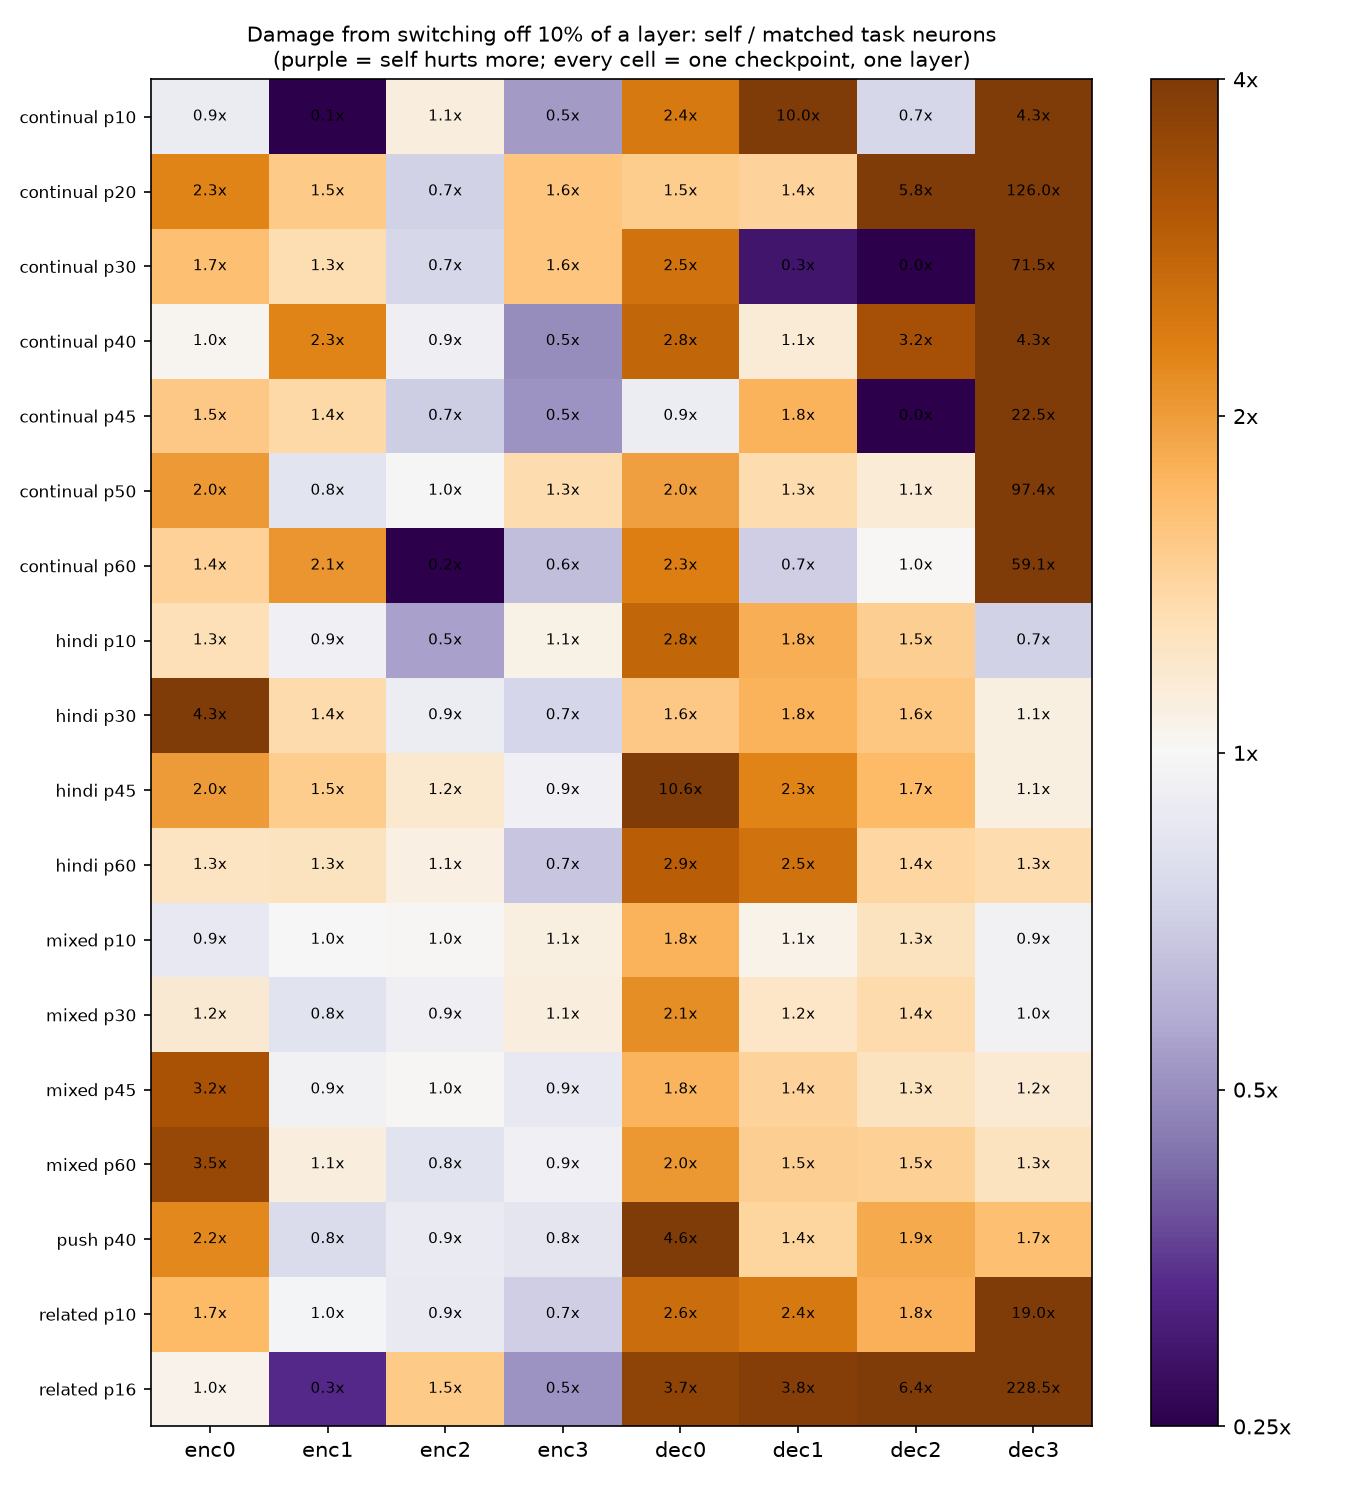

In [4]:
# pool every lesion result (lesion_distant + lesion_distant_more + lesion_indic) into one verdict
run("distant", "--parts", "pool", "--tag", "all")
display(Image("analysis/v8/pool_all/every_checkpoint_every_layer.png"))